# Sector, Geography & Method EDA

Scope matches each source script's original scope (all three FOIA vintages) -- nothing here
changes what was analyzed, only where it lives. The 2000-2009 decade comparison in the first
section is deliberately kept as its full three-file comparison -- that comparison *is* the
finding this section exists to show.


**What this notebook is asking.** Where a loan sits -- industry sector, and to a lesser extent
loan program -- and *when* it originated. This notebook exists mainly to resolve one specific
puzzle: the FY2000-2009 file's elevated chargeoff rate looks alarming at a glance -- is that a
real, decade-wide credit pattern, or an artifact of the 2008 recession sitting inside that file?
The full crosstab pass at the end broadens back out to a general sweep of categorical/continuous
variables against outcome.

In [1]:
import sys
from pathlib import Path

def _find_project_root(marker="sector_eda.py"):
    """Walk up from the current working directory until we find the repo
    root (identified by sector_eda.py sitting next to src/) -- more robust
    than assuming cwd is any particular folder name, which breaks silently
    depending on how Jupyter was launched (plain `jupyter lab`, VS Code, etc.)."""
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / marker).exists() and (candidate / "src").is_dir():
            return candidate
    raise FileNotFoundError(
        f"Could not locate the project root (looked for {marker!r} above {here}). "
        "Run this notebook from somewhere inside the pd-model-sba repo."
    )

PROJECT_ROOT = _find_project_root()
sys.path.insert(0, str(PROJECT_ROOT))
sys.path.insert(0, str(PROJECT_ROOT / "src" / "data_prep"))

import load_sba
import naics_grouping
from sector_eda import load_clean_sector_df, ORDER

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

OUT = str(PROJECT_ROOT / "outputs" / "figures")
COLORS = {"2000_2009": "#4C72B0", "2010_2019": "#DD8452", "2020_Curr": "#55A868"}
pd.set_option("display.width", 160)

## Chargeoff rate by sector and year
Chargeoff rate by sector AND `ApprovalFY` jointly -- checks whether the elevated 2000-2009
resolved-basis chargeoff rate (over 20% in several sectors) is concentrated in specific
years/sectors or spread across the whole decade.

FranchiseCode: nunique changed 5074 -> 5025 after whitespace/case normalization (hidden duplicate categories collapsed)
FranchiseCode: nunique changed 3691 -> 3598 after whitespace/case normalization (hidden duplicate categories collapsed)


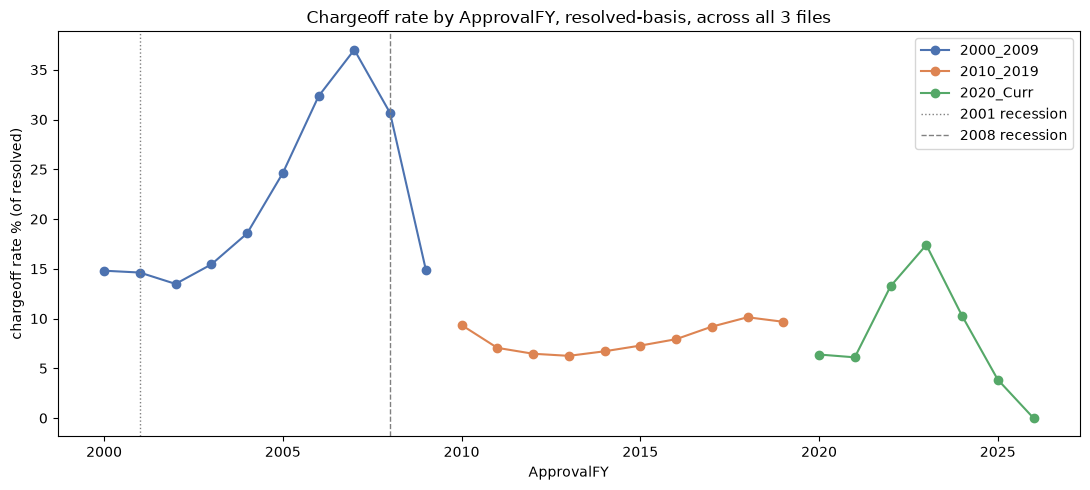

saved 24_chgoffrate_by_year_all_files.png


In [3]:
def chgoff_rate_by_year(df, min_n=30):
    resolved = df[df["LoanStatus"].isin(["PIF", "CHGOFF"])]
    g = resolved.groupby("ApprovalFY")["target"]
    n = g.size()
    rate = g.mean() * 100
    return rate[n >= min_n]


# 1. chargeoff rate by year, all three files on one timeline
fig, ax = plt.subplots(figsize=(11, 5))
for name in ORDER:
    df = load_clean_sector_df(name)
    rate = chgoff_rate_by_year(df)
    ax.plot(rate.index, rate.values, marker="o", label=name, color=COLORS[name])
ax.set_xlabel("ApprovalFY")
ax.set_ylabel("chargeoff rate % (of resolved)")
ax.set_title("Chargeoff rate by ApprovalFY, resolved-basis, across all 3 files")
ax.axvline(2001, color="gray", linestyle=":", linewidth=1, label="2001 recession")
ax.axvline(2008, color="gray", linestyle="--", linewidth=1, label="2008 recession")
ax.legend()
fig.tight_layout()
fig.savefig(f"{OUT}/24_chgoffrate_by_year_all_files.png", dpi=150)
plt.show()
print("saved 24_chgoffrate_by_year_all_files.png")

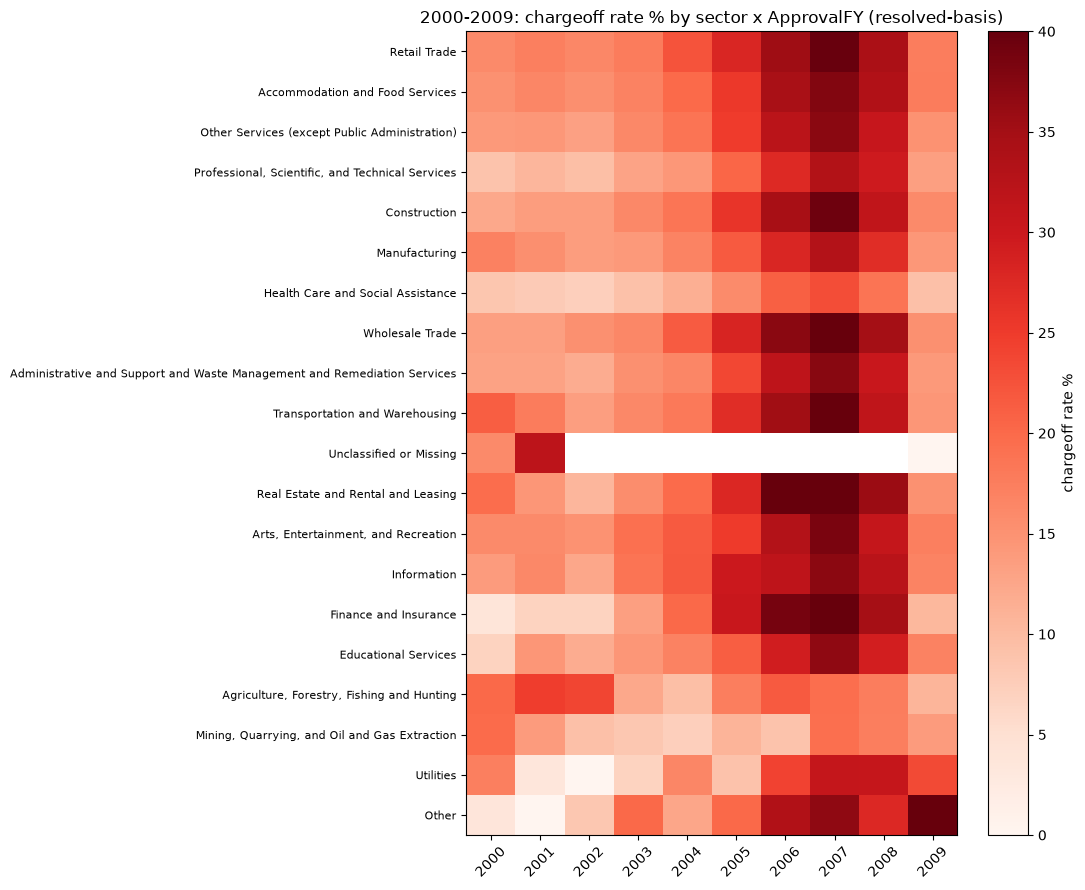

saved 25_sector_x_year_chgoffrate_2000_2009.png

2000-2009 chargeoff rate % by sector x year:
ApprovalFY                                                                2000  2001  2002  2003  2004  2005  2006  2007  2008  2009
NaicsSectorName                                                                                                                     
Retail Trade                                                              16.1  17.2  16.4  17.7  22.4  27.8  35.4  39.8  34.2  17.6
Accommodation and Food Services                                           15.2  16.5  15.3  16.9  20.0  25.4  34.2  37.7  33.3  17.7
Other Services (except Public Administration)                             14.1  14.3  13.1  16.1  18.7  24.9  32.0  37.1  30.5  14.9
Professional, Scientific, and Technical Services                           8.9  10.5   9.4  12.8  14.3  20.5  27.4  33.2  29.6  13.3
Construction                                                              12.3  13.7  13.6  16.1  18.5  25.9

In [4]:
# sector x year heatmap, 2000-2009 specifically (where the puzzle is)
df_0009 = load_clean_sector_df("2000_2009")
resolved_0009 = df_0009[df_0009["LoanStatus"].isin(["PIF", "CHGOFF"])]
pivot_rate = pd.crosstab(resolved_0009["NaicsSectorName"], resolved_0009["ApprovalFY"],
                          values=resolved_0009["target"], aggfunc="mean") * 100
pivot_n = pd.crosstab(resolved_0009["NaicsSectorName"], resolved_0009["ApprovalFY"])
order = df_0009["NaicsSectorName"].value_counts().index
pivot_rate = pivot_rate.reindex(order)

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(pivot_rate.values, aspect="auto", cmap="Reds", vmin=0, vmax=40)
ax.set_xticks(range(len(pivot_rate.columns)))
ax.set_xticklabels(pivot_rate.columns, rotation=45)
ax.set_yticks(range(len(pivot_rate.index)))
ax.set_yticklabels(pivot_rate.index, fontsize=8)
ax.set_title("2000-2009: chargeoff rate % by sector x ApprovalFY (resolved-basis)")
fig.colorbar(im, ax=ax, label="chargeoff rate %")
fig.tight_layout()
fig.savefig(f"{OUT}/25_sector_x_year_chgoffrate_2000_2009.png", dpi=150)
plt.show()
print("saved 25_sector_x_year_chgoffrate_2000_2009.png")
print("\n2000-2009 chargeoff rate % by sector x year:")
print(pivot_rate.round(1).to_string())
print("\ncell counts (resolved loans):")
print(pivot_n.reindex(order).to_string())

**Decade baseline.** Is the 2000-2009 file's elevated chargeoff rate just the 2006-2008 recession
pulling up the decade average, or is the underlying baseline (excluding those years) also elevated
vs. the other two files?

FranchiseCode: nunique changed 5074 -> 5025 after whitespace/case normalization (hidden duplicate categories collapsed)
FranchiseCode: nunique changed 3691 -> 3598 after whitespace/case normalization (hidden duplicate categories collapsed)
                                  chgoff_rate_pct       n
slice                                                    
2000-2009, all years                        23.88  604430
2000-2005 only (pre-recession)              17.99  333730
2000-2009 excluding 2006-2008               17.69  369872
2006-2008 only                              33.65  234558
2010_2019, all years (reference)             7.97  428581
2020_Curr, all years (reference)             9.18   75051


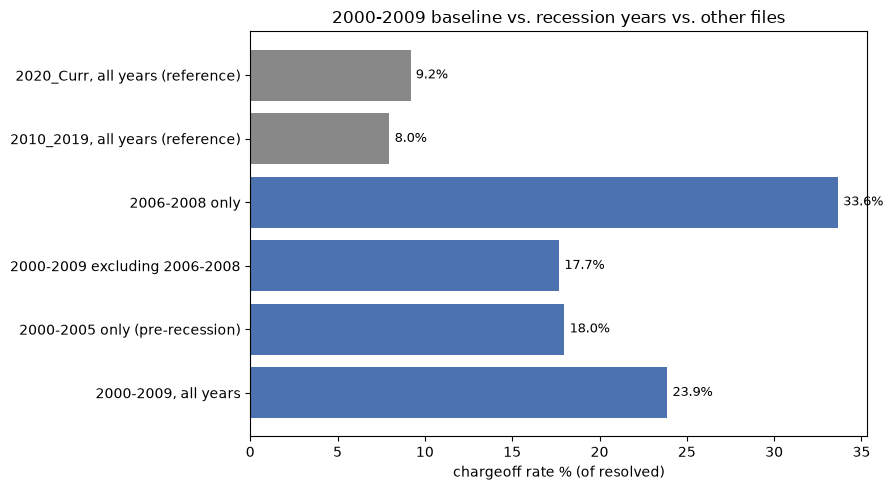

saved /Users/yk/YK/2026/Python/PD_related/PD_project/pd-model-sba/outputs/figures/27_decade_baseline_vs_recession.png


In [5]:
slices = {
    "2000-2009, all years": resolved_0009,
    "2000-2005 only (pre-recession)": resolved_0009[resolved_0009["ApprovalFY"] <= 2005],
    "2000-2009 excluding 2006-2008": resolved_0009[~resolved_0009["ApprovalFY"].isin([2006, 2007, 2008])],
    "2006-2008 only": resolved_0009[resolved_0009["ApprovalFY"].isin([2006, 2007, 2008])],
}
for name in ["2010_2019", "2020_Curr"]:
    d = load_clean_sector_df(name)
    slices[f"{name}, all years (reference)"] = d[d["LoanStatus"].isin(["PIF", "CHGOFF"])]

rows = []
for label, s in slices.items():
    rows.append({"slice": label, "chgoff_rate_pct": s["target"].mean() * 100, "n": len(s)})
baseline_table = pd.DataFrame(rows).set_index("slice")
baseline_table["chgoff_rate_pct"] = baseline_table["chgoff_rate_pct"].round(2)
print(baseline_table.to_string())

fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#4C72B0"] * 4 + ["#888888", "#888888"]
ax.barh(baseline_table.index, baseline_table["chgoff_rate_pct"], color=colors)
ax.set_xlabel("chargeoff rate % (of resolved)")
ax.set_title("2000-2009 baseline vs. recession years vs. other files")
for i, v in enumerate(baseline_table["chgoff_rate_pct"]):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=9)
fig.tight_layout()
fig.savefig(f"{OUT}/27_decade_baseline_vs_recession.png", dpi=150)
plt.show()
print(f"saved {OUT}/27_decade_baseline_vs_recession.png")

## Collateral rate x Express-type ProcessingMethod
Collateral rate and chargeoff rate: Express-type `ProcessingMethod` (SBAEXPRESSPROGRAM,
COMMUNITYEXPRESS) vs. everything else. Checks whether the elevated risk in Express-type/short-term
products lines up with lower collateralization.

In [6]:
EXPRESS_TYPE_METHODS = {"SBAEXPRESSPROGRAM", "COMMUNITYEXPRESS"}

frames = [load_clean_sector_df(name) for name in ORDER]
pooled = pd.concat(frames, ignore_index=True)

pooled["method_group"] = pooled["ProcessingMethod"].apply(
    lambda m: "Express-type" if m in EXPRESS_TYPE_METHODS else "Other"
)

resolved = pooled[pooled["LoanStatus"].isin(["PIF", "CHGOFF"])]
summary = resolved.groupby("method_group").agg(
    n=("target", "size"),
    chgoff_rate_pct=("target", lambda s: s.mean() * 100),
    pct_collateral_Y=("CollateralInd", lambda s: (s == "Y").mean() * 100),
).round(2)

print("Express-type (SBAEXPRESSPROGRAM/COMMUNITYEXPRESS) vs Other ProcessingMethod:")
print(summary)

FranchiseCode: nunique changed 5074 -> 5025 after whitespace/case normalization (hidden duplicate categories collapsed)
FranchiseCode: nunique changed 3691 -> 3598 after whitespace/case normalization (hidden duplicate categories collapsed)
Express-type (SBAEXPRESSPROGRAM/COMMUNITYEXPRESS) vs Other ProcessingMethod:
                   n  chgoff_rate_pct  pct_collateral_Y
method_group                                           
Express-type  623914            19.05             33.01
Other         484148            13.74             51.12


## Full crosstab / chart pass
Crosstabs and charts across categorical + continuous variables vs. chargeoff outcome, on the
pooled, cleaned, NAICS-sector-assigned dataset (all three files, with a `vintage_file` tag) --
most of these are about behavioral patterns, not era comparisons; the exceptions
(`MonthsToChargeoff`, sector dispersion) keep the vintage split explicit.

In [7]:
def chgoff_rate_by(df, col, min_n=30):
    """resolved-only chargeoff rate (CHGOFF / (PIF+CHGOFF)) by a grouping column, event-count filtered."""
    resolved = df[df["LoanStatus"].isin(["PIF", "CHGOFF"])]
    g = resolved.groupby(col)["LoanStatus"]
    n = g.size()
    chgoff = resolved[resolved["LoanStatus"] == "CHGOFF"].groupby(col).size().reindex(n.index).fillna(0)
    rate = (chgoff / n * 100)
    out = pd.DataFrame({"n_resolved": n, "chgoff_events": chgoff, "chgoff_rate_pct": rate})
    return out[out["n_resolved"] >= min_n].sort_values("chgoff_rate_pct", ascending=False)


frames = []
for name in ORDER:
    df = load_clean_sector_df(name)
    df["vintage_file"] = name
    frames.append(df)
pooled = pd.concat(frames, ignore_index=True)
print(f"pooled shape: {pooled.shape}")

FranchiseCode: nunique changed 5074 -> 5025 after whitespace/case normalization (hidden duplicate categories collapsed)
FranchiseCode: nunique changed 3691 -> 3598 after whitespace/case normalization (hidden duplicate categories collapsed)
pooled shape: (1622495, 47)


**LoanStatus mix by sector.**

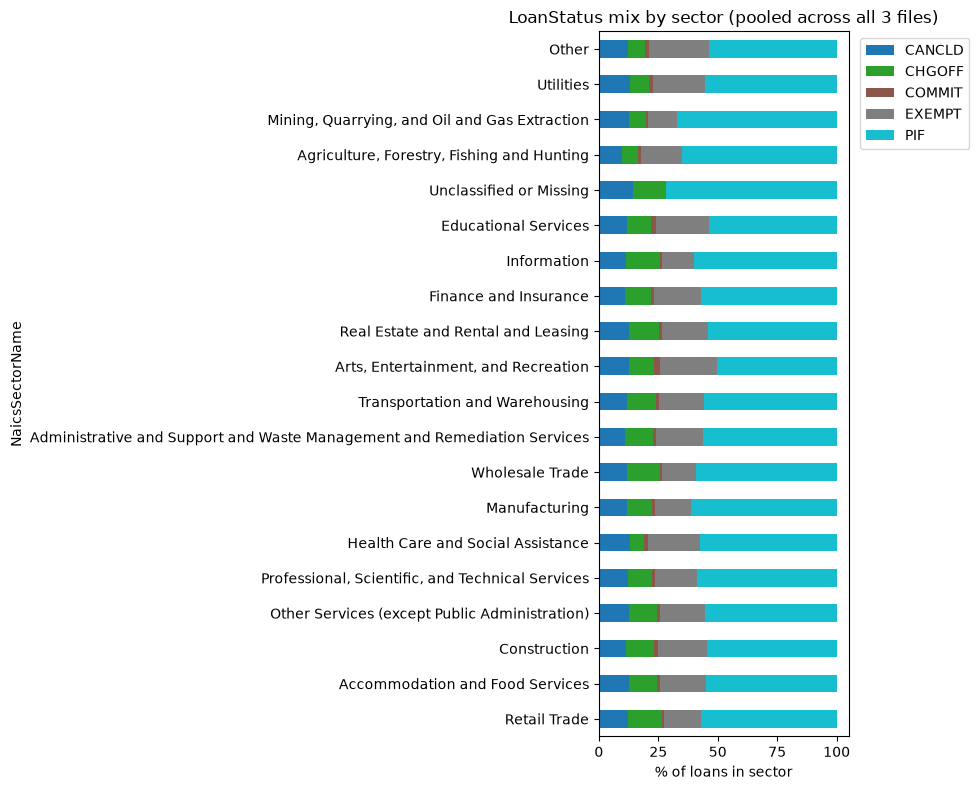

saved 10_loanstatus_by_sector.png


In [8]:
ct = pd.crosstab(pooled["NaicsSectorName"], pooled["LoanStatus"], normalize="index") * 100
ct = ct.loc[pooled["NaicsSectorName"].value_counts().index]
fig, ax = plt.subplots(figsize=(10, 8))
ct.plot(kind="barh", stacked=True, ax=ax, colormap="tab10")
ax.set_xlabel("% of loans in sector")
ax.set_title("LoanStatus mix by sector (pooled across all 3 files)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(f"{OUT}/10_loanstatus_by_sector.png", dpi=150)
plt.show()
print("saved 10_loanstatus_by_sector.png")

**Sector x BusinessAge, sector x BusinessType.**

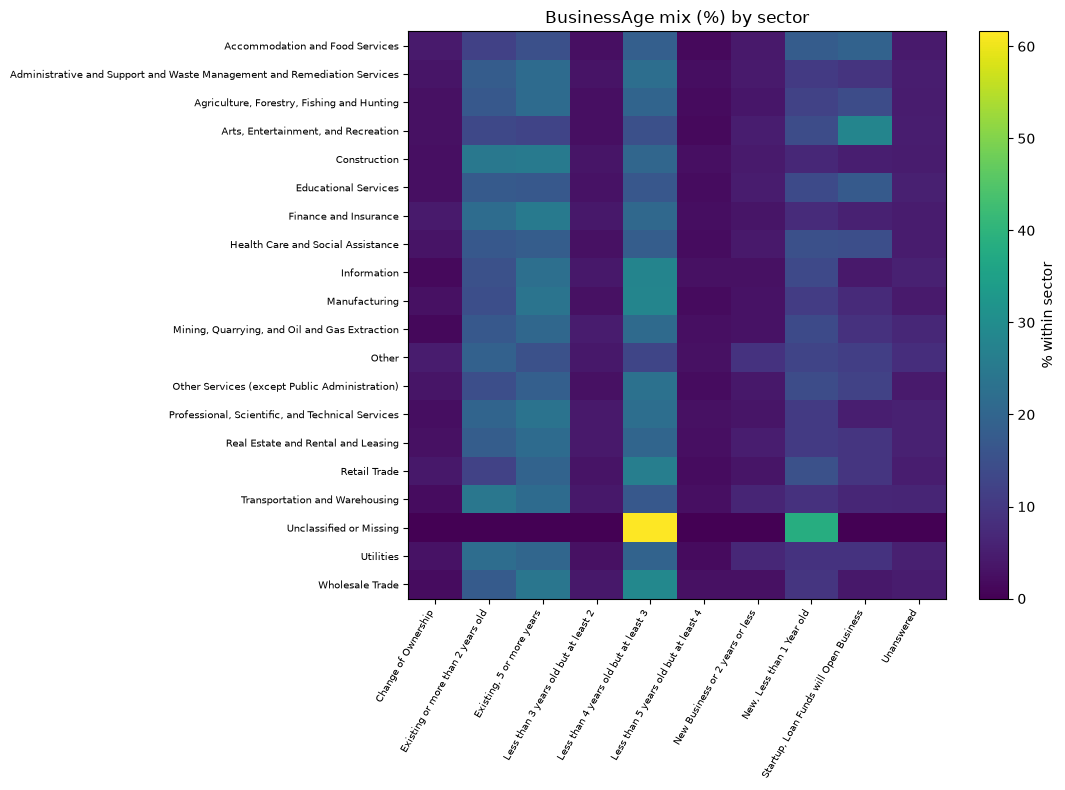

saved 11_sector_vs_businessage.png


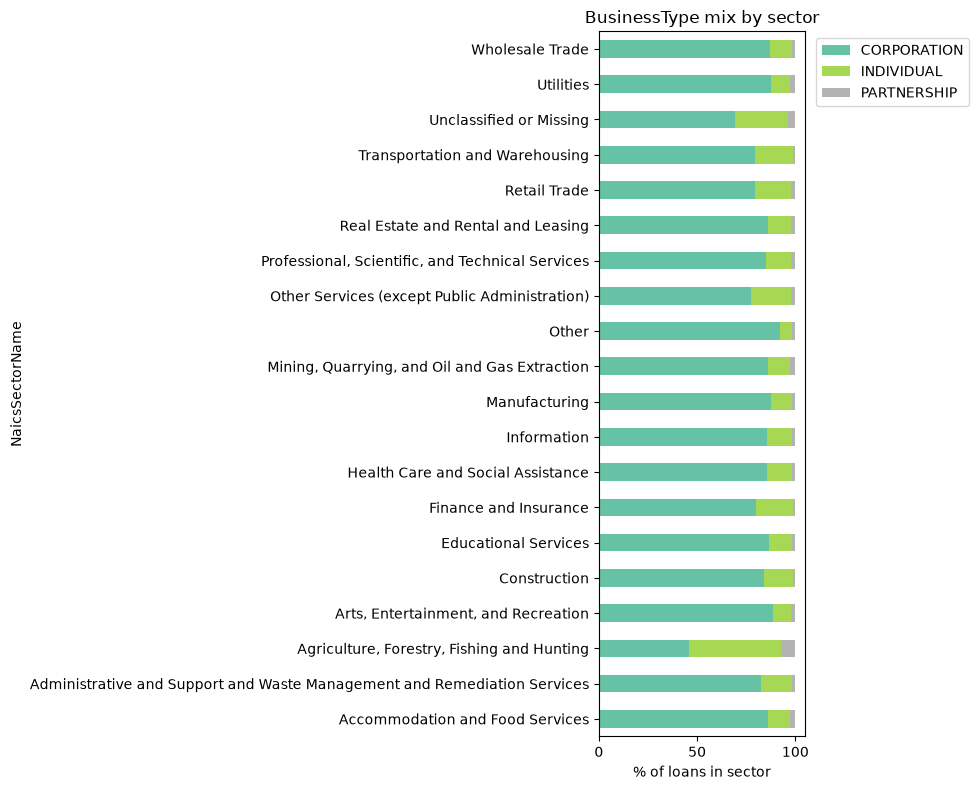

saved 12_sector_vs_businesstype.png


In [8]:
ct = pd.crosstab(pooled["NaicsSectorName"], pooled["BusinessAge"], normalize="index") * 100
fig, ax = plt.subplots(figsize=(11, 8))
im = ax.imshow(ct.values, aspect="auto", cmap="viridis")
ax.set_xticks(range(len(ct.columns)))
ax.set_xticklabels(ct.columns, rotation=60, ha="right", fontsize=7)
ax.set_yticks(range(len(ct.index)))
ax.set_yticklabels(ct.index, fontsize=7)
ax.set_title("BusinessAge mix (%) by sector")
fig.colorbar(im, ax=ax, label="% within sector")
fig.tight_layout()
fig.savefig(f"{OUT}/11_sector_vs_businessage.png", dpi=150)
plt.show()
print("saved 11_sector_vs_businessage.png")

ct = pd.crosstab(pooled["NaicsSectorName"], pooled["BusinessType"], normalize="index") * 100
fig, ax = plt.subplots(figsize=(10, 8))
ct.plot(kind="barh", stacked=True, ax=ax, colormap="Set2")
ax.set_xlabel("% of loans in sector")
ax.set_title("BusinessType mix by sector")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(f"{OUT}/12_sector_vs_businesstype.png", dpi=150)
plt.show()
print("saved 12_sector_vs_businesstype.png")

**ProcessingMethod x chargeoff rate, and GrossApproval size-bucket x chargeoff rate.**

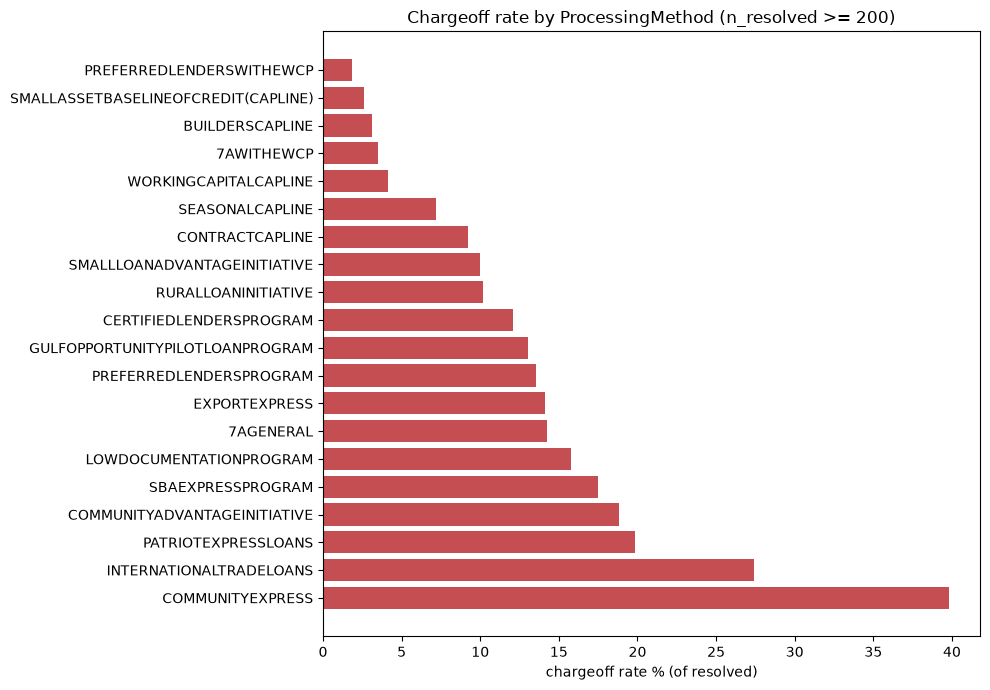

saved 13_processingmethod_vs_chgoffrate.png
                                     n_resolved  chgoff_events  chgoff_rate_pct
ProcessingMethod                                                               
COMMUNITYEXPRESS                          43104        17153.0        39.794451
INTERNATIONALTRADELOANS                    4242         1163.0        27.416313
PATRIOTEXPRESSLOANS                        9622         1907.0        19.819164
COMMUNITYADVANTAGEINITIATIVE               4904          924.0        18.841762
SBAEXPRESSPROGRAM                        580810       101695.0        17.509168
LOWDOCUMENTATIONPROGRAM                   42068         6641.0        15.786346
7AGENERAL                                 86188        12274.0        14.240962
EXPORTEXPRESS                              2356          333.0        14.134126
PREFERREDLENDERSPROGRAM                  284581        38490.0        13.525147
GULFOPPORTUNITYPILOTLOANPROGRAM            2829          368.0        13.008

In [9]:
t = chgoff_rate_by(pooled, "ProcessingMethod", min_n=200)
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(t.index, t["chgoff_rate_pct"], color="#C44E52")
ax.set_xlabel("chargeoff rate % (of resolved)")
ax.set_title("Chargeoff rate by ProcessingMethod (n_resolved >= 200)")
fig.tight_layout()
fig.savefig(f"{OUT}/13_processingmethod_vs_chgoffrate.png", dpi=150)
plt.show()
print("saved 13_processingmethod_vs_chgoffrate.png")
print(t.to_string())

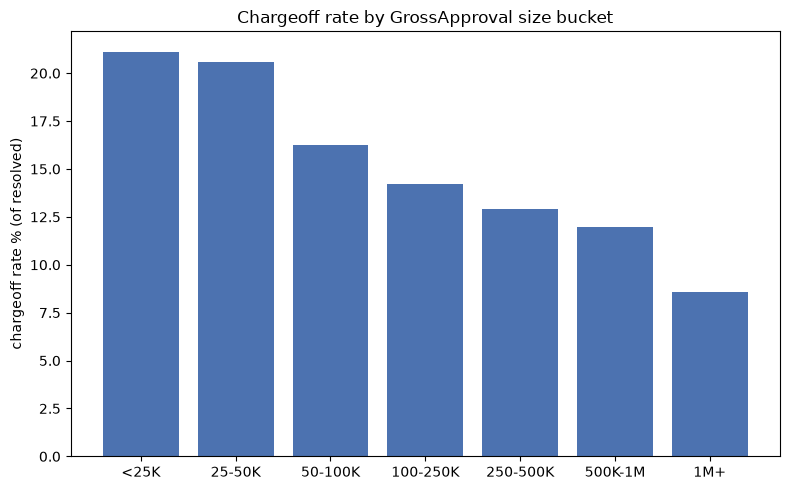

saved 14_loansize_vs_chgoffrate.png


In [10]:
bins = [0, 25000, 50000, 100000, 250000, 500000, 1_000_000, np.inf]
labels = ["<25K", "25-50K", "50-100K", "100-250K", "250-500K", "500K-1M", "1M+"]
pooled["GrossApproval_bucket"] = pd.cut(pooled["GrossApproval"], bins=bins, labels=labels)
t = chgoff_rate_by(pooled, "GrossApproval_bucket", min_n=1)
t = t.reindex(labels)
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(t.index, t["chgoff_rate_pct"], color="#4C72B0")
ax.set_ylabel("chargeoff rate % (of resolved)")
ax.set_title("Chargeoff rate by GrossApproval size bucket")
fig.tight_layout()
fig.savefig(f"{OUT}/14_loansize_vs_chgoffrate.png", dpi=150)
plt.show()
print("saved 14_loansize_vs_chgoffrate.png")

**RevolverStatus and CollateralInd x chargeoff rate + loan size.**

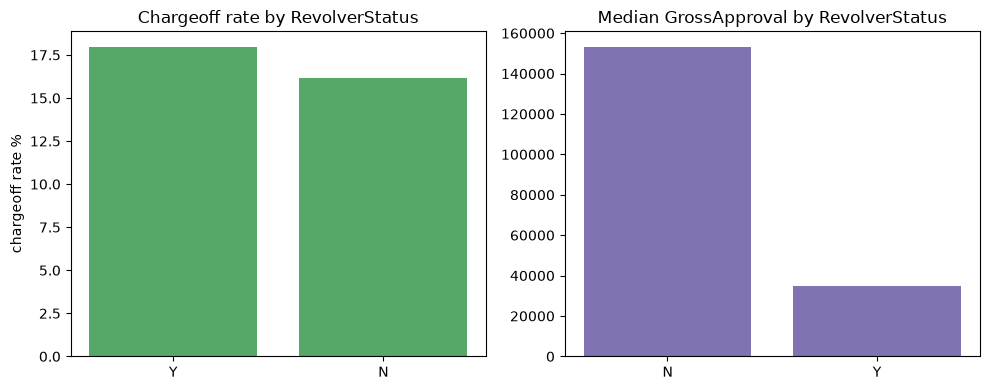

saved 15_revolverstatus_vs_chgoff_amount.png


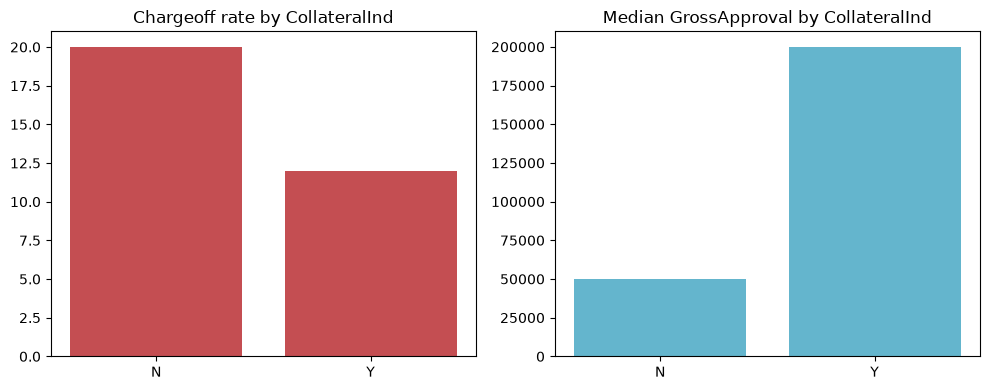

saved 17_collateral_vs_chgoff_amount.png


In [11]:
t = chgoff_rate_by(pooled, "RevolverStatus", min_n=1)
med_amt = pooled.groupby("RevolverStatus")["GrossApproval"].median()
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(t.index.astype(str), t["chgoff_rate_pct"], color="#55A868")
axes[0].set_title("Chargeoff rate by RevolverStatus")
axes[0].set_ylabel("chargeoff rate %")
axes[1].bar(med_amt.index.astype(str), med_amt.values, color="#8172B2")
axes[1].set_title("Median GrossApproval by RevolverStatus")
fig.tight_layout()
fig.savefig(f"{OUT}/15_revolverstatus_vs_chgoff_amount.png", dpi=150)
plt.show()
print("saved 15_revolverstatus_vs_chgoff_amount.png")

t = chgoff_rate_by(pooled, "CollateralInd", min_n=1)
med_amt = pooled.groupby("CollateralInd")["GrossApproval"].median()
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(t.index.astype(str), t["chgoff_rate_pct"], color="#C44E52")
axes[0].set_title("Chargeoff rate by CollateralInd")
axes[1].bar(med_amt.index.astype(str), med_amt.values, color="#64B5CD")
axes[1].set_title("Median GrossApproval by CollateralInd")
fig.tight_layout()
fig.savefig(f"{OUT}/17_collateral_vs_chgoff_amount.png", dpi=150)
plt.show()
print("saved 17_collateral_vs_chgoff_amount.png")

**FixedorVariableInterestInd x chargeoff rate by top ProcessingMethods, and SoldSecMrktInd.**

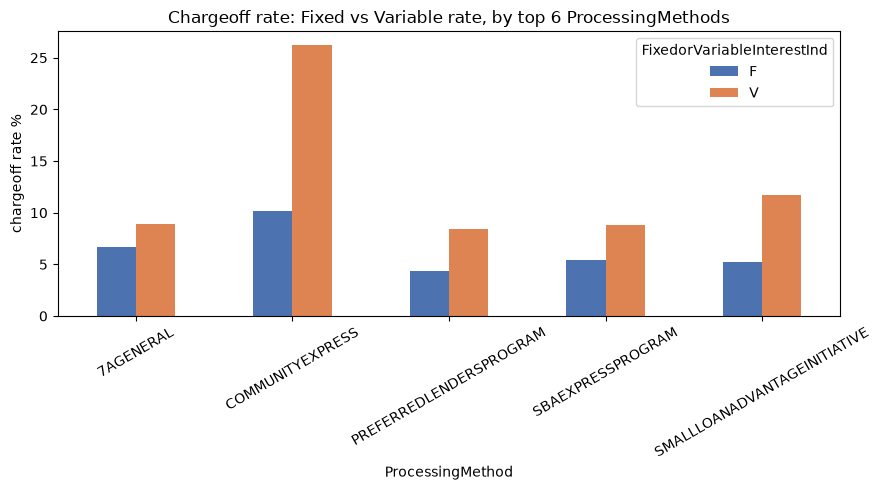

saved 16_fixedvar_vs_chgoff_by_method.png
SoldSecMrktInd chargeoff rate:
                n_resolved  chgoff_events  chgoff_rate_pct
SoldSecMrktInd                                            
N                     4067           3819        93.902139
Y                   263043          50623        19.245142


In [12]:
top_methods = pooled["ProcessingMethod"].value_counts().head(6).index
sub = pooled[pooled["ProcessingMethod"].isin(top_methods)]
resolved_sub = sub[sub["LoanStatus"].isin(["PIF", "CHGOFF"])]
ct = resolved_sub.groupby(["ProcessingMethod", "FixedorVariableInterestInd"])["LoanStatus"].apply(
    lambda s: (s == "CHGOFF").mean() * 100
).unstack()
fig, ax = plt.subplots(figsize=(9, 5))
ct.plot(kind="bar", ax=ax, color=["#4C72B0", "#DD8452"])
ax.set_ylabel("chargeoff rate %")
ax.set_title("Chargeoff rate: Fixed vs Variable rate, by top 6 ProcessingMethods")
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
fig.savefig(f"{OUT}/16_fixedvar_vs_chgoff_by_method.png", dpi=150)
plt.show()
print("saved 16_fixedvar_vs_chgoff_by_method.png")

t = chgoff_rate_by(pooled, "SoldSecMrktInd", min_n=1)
print("SoldSecMrktInd chargeoff rate:")
print(t.to_string())

**MonthsToChargeoff distribution, by sector and by vintage file.**

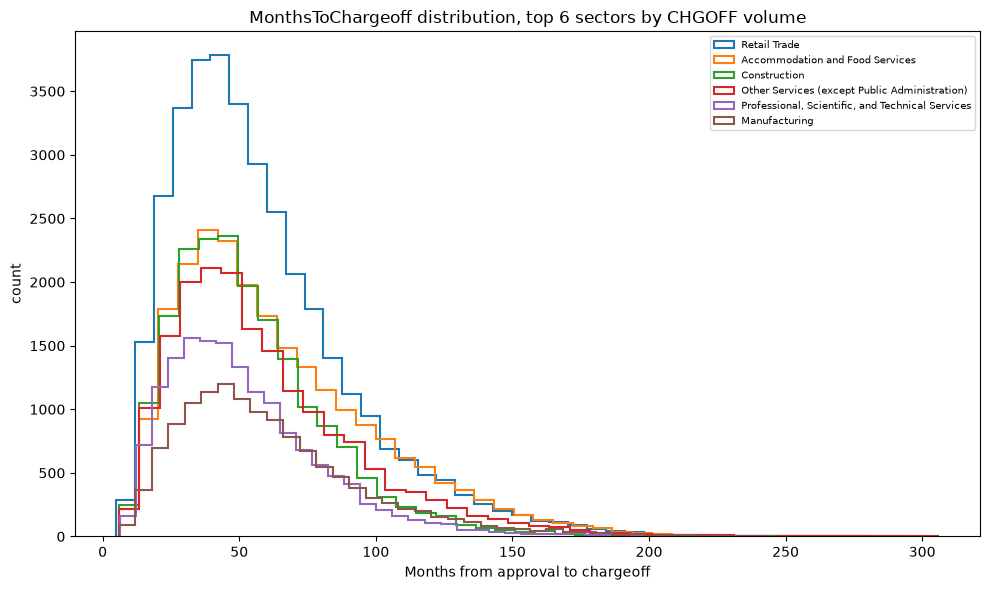

saved 19_monthstochgoff_by_sector.png


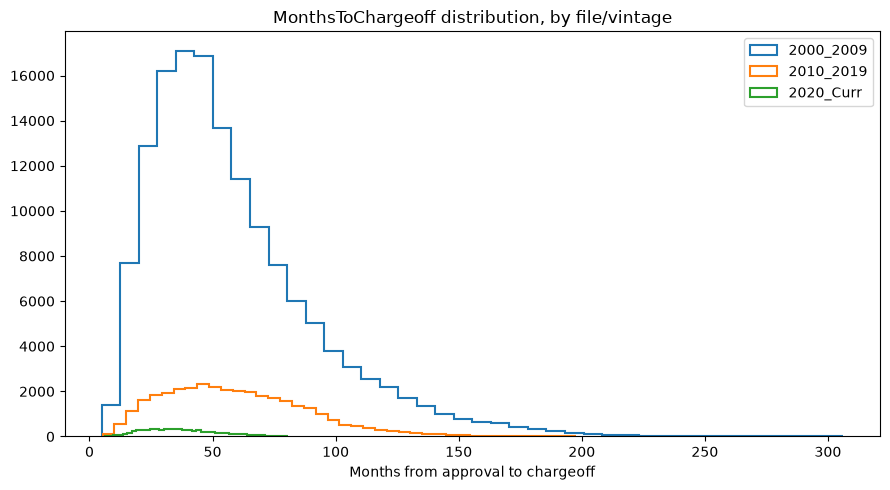

saved 20_monthstochgoff_by_vintage.png


In [13]:
chgoff_rows = pooled[pooled["LoanStatus"] == "CHGOFF"].copy()
chgoff_rows["MonthsToChargeoff"] = (
    (chgoff_rows["ChargeOffDate"] - chgoff_rows["ApprovalDate"]).dt.days / 30.44
)
top_sectors = chgoff_rows["NaicsSectorName"].value_counts().head(6).index
fig, ax = plt.subplots(figsize=(10, 6))
for sector in top_sectors:
    vals = chgoff_rows.loc[chgoff_rows["NaicsSectorName"] == sector, "MonthsToChargeoff"].dropna()
    ax.hist(vals, bins=40, histtype="step", label=sector, linewidth=1.5)
ax.set_xlabel("Months from approval to chargeoff")
ax.set_ylabel("count")
ax.set_title("MonthsToChargeoff distribution, top 6 sectors by CHGOFF volume")
ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(f"{OUT}/19_monthstochgoff_by_sector.png", dpi=150)
plt.show()
print("saved 19_monthstochgoff_by_sector.png")

fig, ax = plt.subplots(figsize=(9, 5))
for name in ORDER:
    vals = chgoff_rows.loc[chgoff_rows["vintage_file"] == name, "MonthsToChargeoff"].dropna()
    ax.hist(vals, bins=40, histtype="step", label=name, linewidth=1.5)
ax.set_xlabel("Months from approval to chargeoff")
ax.set_title("MonthsToChargeoff distribution, by file/vintage")
ax.legend()
fig.tight_layout()
fig.savefig(f"{OUT}/20_monthstochgoff_by_vintage.png", dpi=150)
plt.show()
print("saved 20_monthstochgoff_by_vintage.png")

**State (ProjectState) x chargeoff rate, and CANCLD rate by sector.**

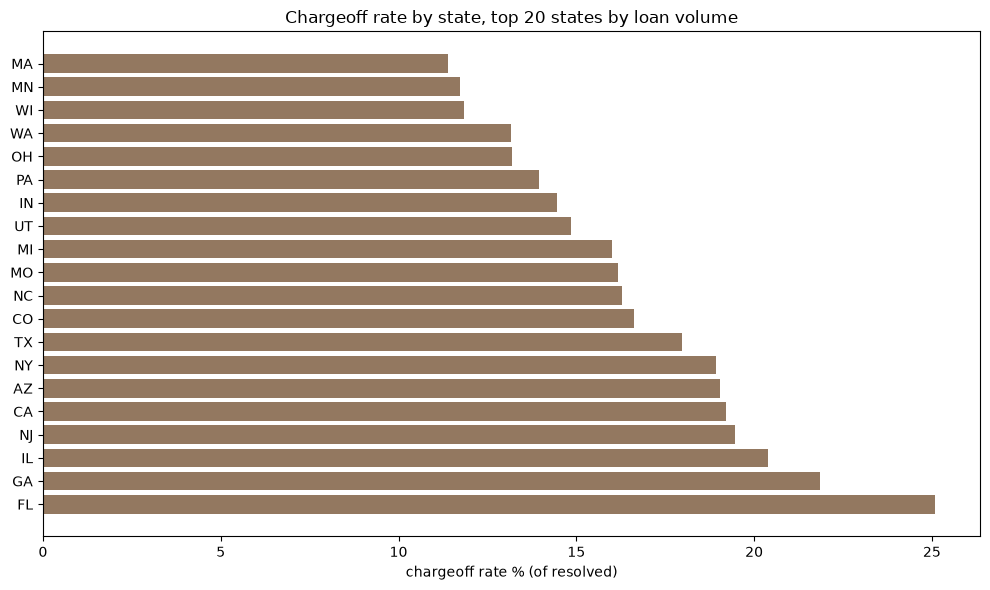

saved 21_state_vs_chgoffrate.png


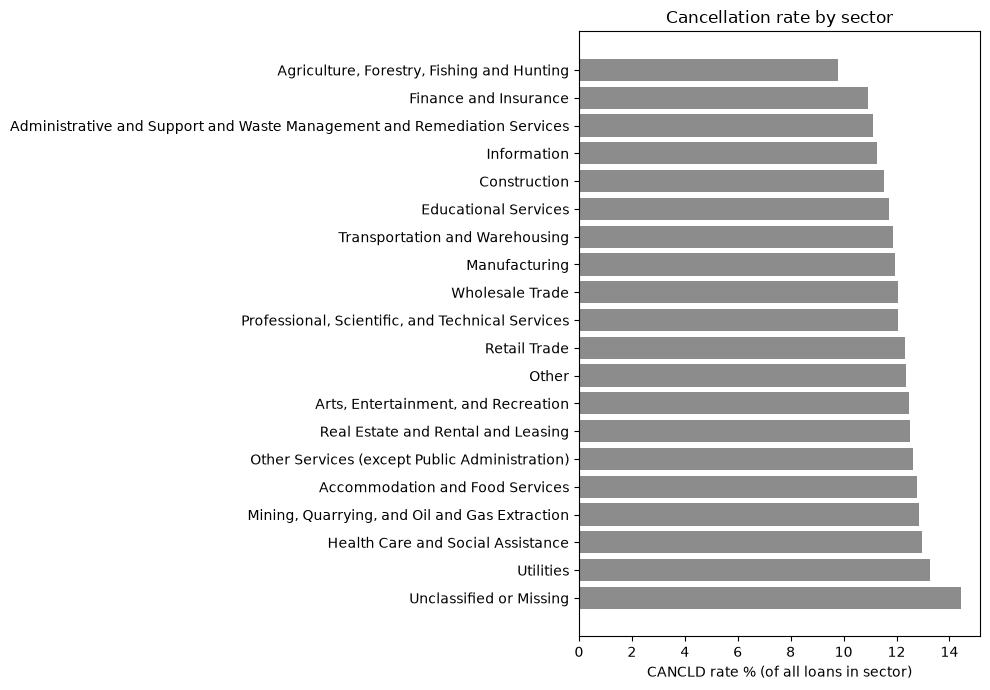

saved 22_cancld_rate_by_sector.png

ALL DONE


In [14]:
top_states = pooled["ProjectState"].value_counts().head(20).index
t = chgoff_rate_by(pooled[pooled["ProjectState"].isin(top_states)], "ProjectState", min_n=1)
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(t.index, t["chgoff_rate_pct"], color="#937860")
ax.set_xlabel("chargeoff rate % (of resolved)")
ax.set_title("Chargeoff rate by state, top 20 states by loan volume")
fig.tight_layout()
fig.savefig(f"{OUT}/21_state_vs_chgoffrate.png", dpi=150)
plt.show()
print("saved 21_state_vs_chgoffrate.png")

total = pooled.groupby("NaicsSectorName").size()
cancld = pooled[pooled["LoanStatus"] == "CANCLD"].groupby("NaicsSectorName").size().reindex(total.index).fillna(0)
cancld_rate = (cancld / total * 100).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(cancld_rate.index, cancld_rate.values, color="#8C8C8C")
ax.set_xlabel("CANCLD rate % (of all loans in sector)")
ax.set_title("Cancellation rate by sector")
fig.tight_layout()
fig.savefig(f"{OUT}/22_cancld_rate_by_sector.png", dpi=150)
plt.show()
print("saved 22_cancld_rate_by_sector.png")
print("\nALL DONE")

## What this notebook tells us

- **The 2000-2009 elevated rate is not just the 2008 recession.** The decade-baseline comparison
  shows the pre-recession (2000-2005) and recession-excluded slices are still elevated relative to
  the 2010-2019/2020-Curr files -- see the printed baseline table for the exact numbers. This is a
  broader, decade-wide pattern, not a 3-year spike pulling up an otherwise-normal average.
- **Express-type ProcessingMethod loans carry more risk and less collateral** -- consistent with
  the working-capital-loan-risk literature referenced in the source script's docstring.
- **The full crosstab pass** surfaces the usual suspects (loan size, RevolverStatus, CollateralInd,
  ProcessingMethod all show real chargeoff-rate separation) plus two dispersion checks
  (MonthsToChargeoff by sector and by vintage) worth keeping in mind when interpreting any
  single-vintage chart elsewhere in this project.